# Loan default: baseline models and preprocessing pipeline
**Goal:** set a baseline score, then test whether the text columns and engineered features improve it.
**Data:** 255,347 loans loaded from Postgres, 16 features after dropping `LoanID` and the target `Default`.
**Approach:** stratified 80/20 split; baselines (dummy, logistic regression, balanced weights, threshold tuning) on 12 numeric columns; then a `ColumnTransformer` pipeline that adds the 4 text columns and 2 engineered features.

## 1. Imports and data
Load the `loans` table from Postgres. The three Yes/No columns are already stored as 1/0.

In [15]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from loan_data import read_from_db
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix, precision_score, f1_score, roc_auc_score, average_precision_score, RocCurveDisplay, ConfusionMatrixDisplay, classification_report

FIG = Path("../reports/figures")
FIG.mkdir(parents=True,exist_ok=True)

df = read_from_db()
print(df.shape)
df.dtypes

(255347, 18)


LoanID                str
Age                 int64
Income              int64
LoanAmount          int64
CreditScore         int64
MonthsEmployed      int64
NumCreditLines      int64
InterestRate      float64
LoanTerm            int64
DTIRatio          float64
Education             str
EmploymentType        str
MaritalStatus         str
HasMortgage         int64
HasDependents       int64
LoanPurpose           str
HasCoSigner         int64
Default             int64
dtype: object

## 2. Features, target and stratified split
`X` holds the features and `y` the target `Default`. `LoanID` is dropped because it only identifies a row. The split is stratified, so both parts keep the same default rate, and `random_state=42` makes it repeatable. The test set stays untouched until evaluation.

In [16]:
X = df.drop(columns=["LoanID", "Default"])
y = df["Default"]

X_train, X_test, y_train, y_test=train_test_split(
    X, y, test_size = 0.2, stratify=y, random_state=42
)
print(X_train.shape,X_test.shape)
print("Default rate: ", y_train.mean())
print("test: ", y_test.mean())

(204277, 16) (51070, 16)
Default rate:  0.11612663197521013
test:  0.11613471705502251


**Check:** 204,277 training rows and 51,070 test rows. Default rate is 11.61% in both, so the stratified split worked.

## 3. Dummy baseline
A model that always predicts "no default". It shows the accuracy that needs no skill at all.

In [17]:
num_cols = X.select_dtypes("number").columns.to_list()
print(len(num_cols), num_cols)

dummy = DummyClassifier(strategy="most_frequent").fit(X_train[num_cols], y_train)
dummy_pred = dummy.predict(X_test[num_cols])
print("Dummy accuracy: ", accuracy_score(y_test, dummy_pred))
print("Dummy recall: ", recall_score(y_test, dummy_pred))

12 ['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'HasMortgage', 'HasDependents', 'HasCoSigner']
Dummy accuracy:  0.8838652829449775
Dummy recall:  0.0


**Finding:** the dummy scores 88.4% accuracy with 0% recall. High accuracy here means nothing, because it simply equals the share of repaid loans. This is why I judge models on recall, precision, F1 and ROC-AUC.

## 4. Logistic regression (numeric features only)
Scaling and the model sit in one pipeline, so the scaler learns only from the training data. Text columns (education, employment type, marital status, loan purpose) are left out for now and will be encoded in a pipeline on Day 10.

In [18]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train[num_cols], y_train)

train_pred = model.predict(X_train[num_cols])
test_pred = model.predict(X_test[num_cols])
print("train accuracy: ",accuracy_score(y_train, train_pred))
print("test accuracy: ",accuracy_score(y_test, test_pred))
print("test recall: ",recall_score(y_test, test_pred))
print(confusion_matrix(y_test, test_pred))

train accuracy:  0.8849062792189037
test accuracy:  0.8845310358331702
test recall:  0.023604788399932557
[[45033   106]
 [ 5791   140]]


**Finding:** test accuracy is 88.5% against 88.4% for the dummy, and recall is only 2.4% (140 of 5,931 defaults caught). Train accuracy (88.5%) is almost the same as test accuracy, so the model is not overfitting; it is just predicting "no default" almost every time.

| | Predicted repaid | Predicted default |
|---|---|---|
| **Actually repaid** | 45,033 | 106 |
| **Actually defaulted** | 5,791 | 140 |

## 5. Logistic regression with balanced class weights
`class_weight="balanced"` makes mistakes on the rare default class cost more, so the model tries harder to find defaults.

In [19]:
model_bal = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight = "balanced"))
model_bal.fit(X_train[num_cols],y_train)

bal_pred = model_bal.predict(X_test[num_cols])
print("Accuracy: ", accuracy_score(y_test,bal_pred))
print("recall: ", recall_score(y_test,bal_pred))
print(confusion_matrix(y_test,bal_pred))

Accuracy:  0.6718817309575092
recall:  0.6990389479008599
[[30167 14972]
 [ 1785  4146]]


**Finding:** recall jumps from 2.4% to 69.9% (4,146 of 5,931 defaults caught), but accuracy drops to 67.2%. The price is 14,972 repaid loans flagged as risky, so only 21.7% of flagged loans really default. This trade-off between catching defaults and false alarms is the main decision for the next stage.

## 6. Full evaluation metrics
Accuracy misleads on imbalanced data, so I compare the three models on precision, recall, F1, ROC-AUC and PR-AUC. ROC-AUC and PR-AUC use predicted probabilities, so they judge how well a model ranks loans, independent of the 0.5 cutoff.

In [ ]:
models = {"Dummy":dummy, "Logistic":model, "Logistic (Balanced)":model_bal}

rows = {}
for name, m in models.items():
    p = m.predict(X_test[num_cols])
    proba_m = m.predict_proba(X_test[num_cols])[:,1]
    rows[name] = {
        "Accuracy":accuracy_score(y_test,p),
        "Precision":precision_score(y_test,p, zero_division=0),
        "Recall":recall_score(y_test,p),
        "F1":f1_score(y_test,p,zero_division=0),
        "ROC_AUC":roc_auc_score(y_test, proba_m),
        "PR_AUC":average_precision_score(y_test, proba_m),
    }
results = pd.DataFrame(rows).T.round(3)
results

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Dummy,0.884,0.000,0.000,0.000,0.500,0.116
Logistic,0.885,0.569,0.024,0.045,0.747,0.300
Logistic (Balanced),0.672,0.217,0.699,0.331,0.747,0.299


**Finding:**
- ROC-AUC is 0.747 for both logistic models, so class weights do not improve how well loans are ranked; they only change which loans get flagged.
- PR-AUC is about 0.30, against 0.116 for the dummy (the default rate), so the model is about 2.6 times better than guessing, but far from strong.
- The balanced model has the best F1 (0.331) at the default 0.5 cutoff, because plain logistic regression almost never predicts a default (F1 0.045).

## 7. Confusion matrices
Rows show the true outcome and columns the predicted outcome.

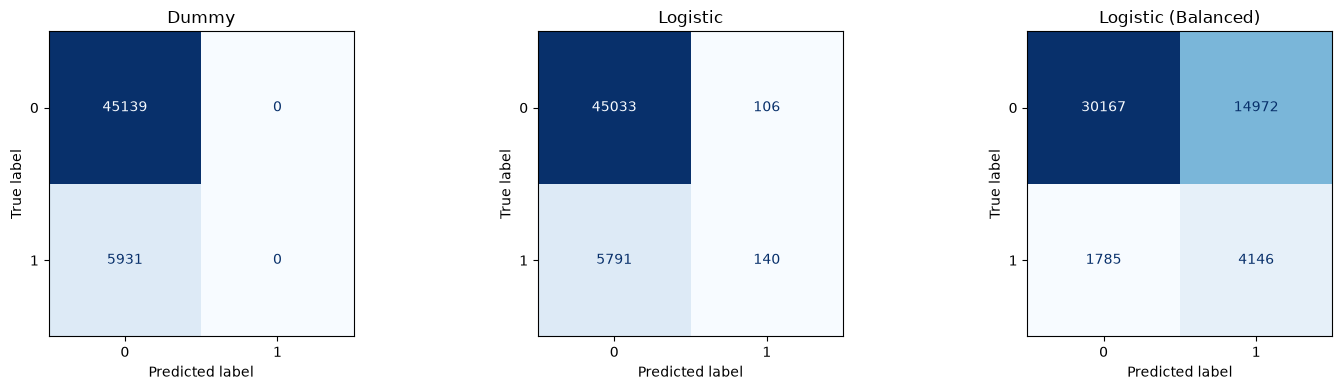

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax , (name, m) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test[num_cols], y_test,ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name)
plt.tight_layout()
plt.savefig(FIG / "06_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:**
- The dummy never flags a default (0 of 5,931 caught).
- Plain logistic regression flags only 246 loans and catches 140 defaults, missing 5,791.
- The balanced model catches 4,146 defaults but flags 14,972 repaid loans by mistake.

## 8. ROC curves
A curve closer to the top left is better. The dashed diagonal is random guessing.

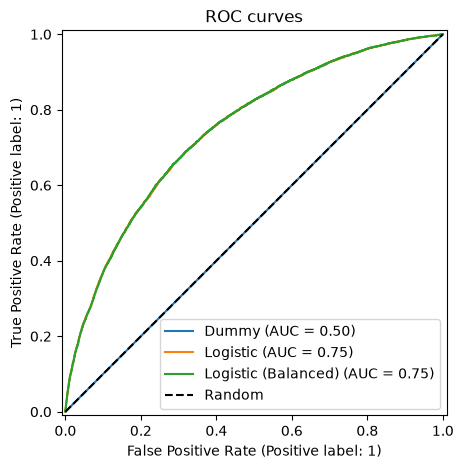

In [22]:
fig, ax = plt.subplots(figsize=(6,5))
for name, m in models.items():
    RocCurveDisplay.from_estimator(m, X_test[num_cols],y_test,ax=ax, name=name,)
ax.plot([0, 1], [0,1 ], "k--",label="Random")
ax.legend()
ax.set_title("ROC curves")
plt.savefig(FIG / "07_roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** the plain and balanced logistic curves are identical (AUC 0.75), so only the green line is visible. The dummy sits on the diagonal (AUC 0.50). The ranking ability is moderate, which fits the weak signals seen in the EDA.

## 9. Threshold experiment
By default a loan is flagged when its predicted default probability is at least 0.5. With only 11.6% defaults, the plain model rarely reaches that. Here I move the cutoff without retraining.

In [23]:
proba_plain = model.predict_proba(X_test[num_cols])[:,1]

thr_rows = []
for t in [0.05,0.10,0.15,0.20,0.30,0.50]:
    p = (proba_plain >= t).astype(int)
    thr_rows.append({
        "threshold": t,
        "flagged":int(p.sum()),
        "Precision": precision_score(y_test, p, zero_division=0),
        "Recall":recall_score(y_test, p),
        "F1":f1_score(y_test, p, zero_division=0)
    })
pd.DataFrame(thr_rows).round(3)

,threshold,flagged,Precision,Recall,F1
0,0.05,37013,0.148,0.925,0.256
1,0.10,22477,0.200,0.758,0.317
2,0.15,13709,0.250,0.579,0.349
3,0.20,8471,0.302,0.431,0.355
4,0.30,3161,0.403,0.215,0.280
5,0.50,246,0.569,0.024,0.045


**Finding:**
- Lowering the threshold raises recall and lowers precision. At 0.05, recall is 92.5% but 37,013 of 51,070 loans (72%) are flagged and precision is only 14.8%.
- F1 peaks around a threshold of 0.20: precision 30.2%, recall 43.1%, 8,471 loans flagged, F1 0.355.
- That F1 beats the balanced-weights model (0.331), so choosing a threshold gives a better balance than `class_weight` alone.
- **Caveat:** I picked the threshold using the test set, so this score is slightly optimistic. Later I will choose the threshold on a validation split or with cross-validation, and keep the test set for the final number.

## Baseline results (numeric features only)
| Model | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|
| Dummy (always "no default") | 0.884 | 0.000 | 0.000 | 0.000 | 0.500 | 0.116 |
| Logistic regression | 0.885 | 0.569 | 0.024 | 0.045 | 0.747 | 0.300 |
| Logistic regression, balanced weights | 0.672 | 0.217 | 0.699 | 0.331 | 0.747 | 0.299 |
| Logistic regression, threshold 0.20 | 0.818 | 0.302 | 0.431 | 0.355 | 0.747 | 0.300 |

**Takeaways**
- Accuracy alone is misleading on this imbalanced data.
- Class weights and threshold changes both trade precision for recall, and they do not change ROC-AUC.
- The best F1 so far is 0.355, from a lowered threshold. Next: encode the text columns, add a pipeline, and try tree-based models.

## 10. Preprocessing pipeline (Day 10)
A `ColumnTransformer` scales the 12 numeric columns (the 3 Yes/No columns are already stored as 0/1) and one-hot encodes the 4 text columns. It is fitted on the training data only and then applied unchanged to the test data. `handle_unknown="ignore"` stops unseen categories from crashing predictions. Every variant uses balanced class weights, so the comparison is fair.

In [24]:
cat_cols = ["EmploymentType", "Education", "LoanPurpose", "MaritalStatus"]
assert len(num_cols) + len(cat_cols) == X.shape[1]

def build_pipeline(numeric,class_weight=None):
    pre = ColumnTransformer([
        ("num", StandardScaler(), numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ])
    return make_pipeline(pre, LogisticRegression(max_iter=1000, class_weight=class_weight))
pipe_cat = build_pipeline(num_cols, class_weight="balanced")
pipe_cat.fit(X_train, y_train)
proba_cat = pipe_cat.predict_proba(X_test)[:,1]

**Check:** 12 numeric + 4 text columns = 16 features, so no column is dropped.

### Comparing variants
ROC-AUC and PR-AUC are the main comparison, because they do not depend on the 0.5 cutoff. Precision, recall and F1 are shown at the default 0.5 threshold.

In [25]:
def report(name,proba,threshold=0.5):
    p = (proba >= threshold).astype(int)
    return{
        "model":name,
        "ROC_AUC":roc_auc_score(y_test, proba),
        "PR_AUC":average_precision_score(y_test, proba),
        "Precision":precision_score(y_test, p, zero_division=0),
        "Recall":recall_score(y_test, p),
        "F1":f1_score(y_test, p, zero_division=0),
    }
proba_num = model_bal.predict_proba(X_test[num_cols])[:,1]
comparsion = pd.DataFrame([
    report("Numeric_only", proba_num),
    report("+ Categorical_only", proba_cat)
]).set_index("model").round(3)
comparsion

,ROC_AUC,PR_AUC,Precision,Recall,F1
model,,,,,
Numeric_only,0.747,0.299,0.217,0.699,0.331
+ Categorical_only,0.753,0.311,0.220,0.699,0.334


### Engineered features
- `LoanToIncome` = loan amount / income
- `AnnualInterestCost` = loan amount x interest rate / income

Both use only feature columns, never the target, so they cannot leak the answer.

In [ ]:
def add_features(d):
    d = d.copy()
    d["LoanToIncome"] = d["LoanAmount"] / d["Income"]
    d["AnnualInterestCost"] = d["LoanAmount"] * d["InterestRate"] / 100 / d["Income"]
    return d
X_train_fe, X_test_fe = add_features(X_train), add_features(X_test)
num_fe = num_cols + ["LoanToIncome", "AnnualInterestCost"]
pipe_fe = build_pipeline(num_fe, class_weight="balanced")
pipe_fe.fit(X_train_fe, y_train)
proba_fe = pipe_fe.predict_proba(X_test_fe)[:,1]

comparsion = pd.DataFrame([
    report("Numeric_only", proba_num),
    report("+Categorical_only", proba_cat),
    report("+Engineered features", proba_fe)
]).set_index("model").round(3)
comparsion

,ROC_AUC,PR_AUC,Precision,Recall,F1
model,,,,,
Numeric_only,0.747,0.299,0.217,0.699,0.331
+ Categorical_only,0.753,0.311,0.220,0.699,0.334
+ Engineered features,0.762,0.336,0.228,0.697,0.344


| Model (balanced weights) | ROC-AUC | PR-AUC | Precision | Recall | F1 |
|---|---|---|---|---|---|
| Numeric only (12 features) | 0.747 | 0.299 | 0.217 | 0.699 | 0.331 |
| + categorical columns (16 features) | 0.753 | 0.311 | 0.220 | 0.699 | 0.334 |
| + engineered features (18 features) | 0.762 | 0.336 | 0.228 | 0.697 | 0.344 |

**Findings:**
- Adding the text columns raises ROC-AUC by 0.006, a small gain that fits the 2 to 3 point category differences in the EDA.
- The two engineered ratios add another 0.009 (0.015 in total) and lift PR-AUC from 0.299 to 0.336, the biggest improvement so far.
- Recall stays near 0.70 because the threshold is fixed at 0.5 with balanced weights; the gain shows up as better precision and ranking.
- The gains are modest. A linear model is limited here, so tree-based models are the next step. I will confirm the differences with cross-validation, since a single test split has some noise.

### What the model uses: coefficients
Logistic regression gives each feature a weight (coefficient). A positive weight pushes a loan towards default and a negative one towards repaid. Numeric columns were scaled, so their weights are per one standard deviation; one-hot weights are for switching a category on. `exp(coefficient)` is the odds ratio.

In [48]:
names = pipe_fe.named_steps["columntransformer"].get_feature_names_out()
coef = pipe_fe.named_steps["logisticregression"].coef_[0]

coef_df = pd.DataFrame({"features":names, "coefficient":coef})
coef_df["features"] = coef_df["features"].str.replace("num__","", regex=False).str.replace("cat__","",regex=False)
coef_df["Odd_ratio"] = np.exp(coef_df["coefficient"])
coef_df = coef_df.reindex(coef_df["coefficient"].abs().sort_values(ascending=False).index).round(3)
print(len(coef_df))
coef_df

30


,features,coefficient,Odd_ratio
0,Age,-0.592,0.553
12,LoanToIncome,0.490,1.633
6,InterestRate,0.478,1.612
4,MonthsEmployed,-0.341,0.711
14,EmploymentType_Full-time,-0.284,0.752
25,LoanPurpose_Home,-0.198,0.820
28,MaritalStatus_Married,-0.178,0.837
21,Education_PhD,-0.165,0.848
17,EmploymentType_Unemployed,0.152,1.164
11,HasCoSigner,-0.132,0.876


### What the model uses: largest coefficients
The chart shows the 15 largest of the 30 logistic regression weights. A red bar pushes a loan towards default and a blue bar towards repaid. Numeric columns were scaled, so their bars are per one standard deviation; text and Yes/No columns are for switching a category on. `exp(coefficient)` gives the odds ratio.

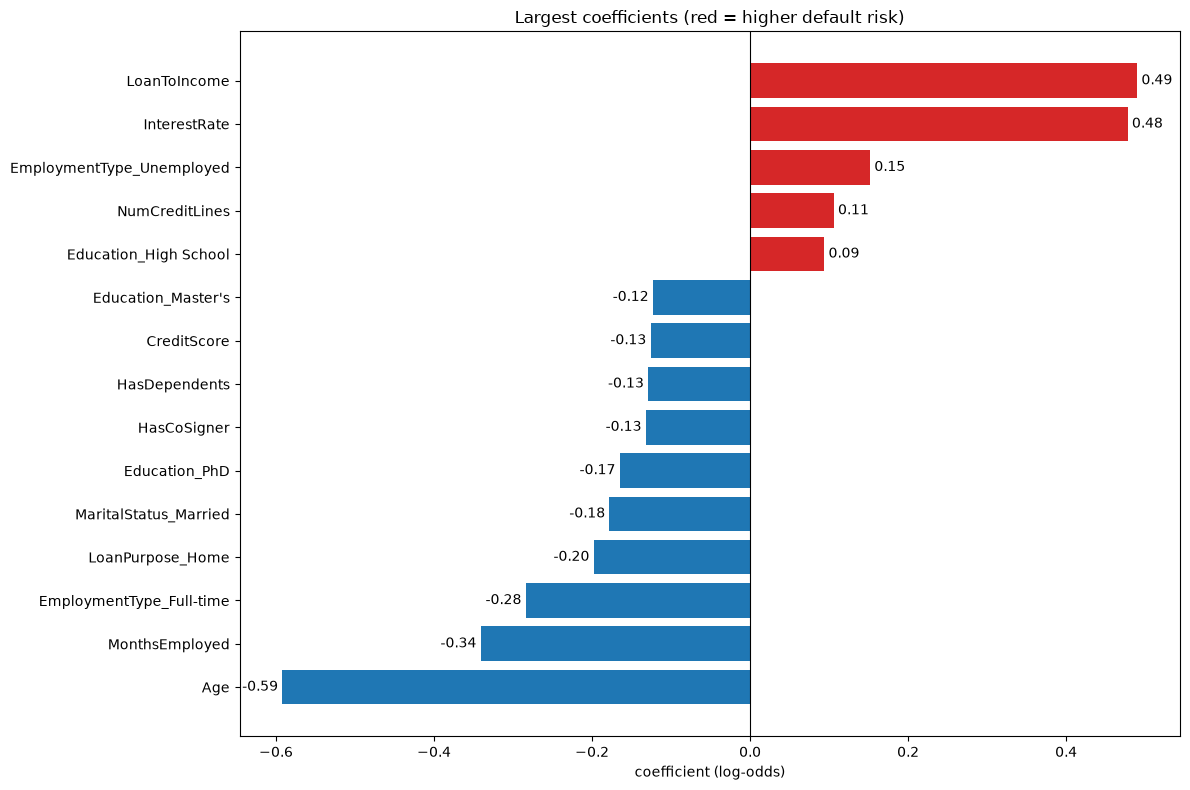

In [68]:
top = coef_df.head(15).sort_values("coefficient")
fig , ax = plt.subplots(figsize=(12,8))
bars = plt.barh(top["features"], top["coefficient"], color=["tab:red" if c > 0 else "tab:blue" for c in top["coefficient"]])
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.axvline(0, color="black", linewidth=0.8 )
ax.set_title("Largest coefficients (red = higher default risk)")
ax.set_xlabel("coefficient (log-odds)")
plt.tight_layout()
plt.savefig(FIG / "08_coefficients.png", dpi=150, bbox_inches="tight")
plt.show()

**Findings:**
- **Strongest push towards default:** loan-to-income ratio (+0.49, odds ratio about 1.63) and interest rate (+0.48, about 1.61). Unemployed (+0.15), number of credit lines (+0.11) and High School education (+0.09) also raise risk, but much less.
- **Strongest push towards repaid:** age (-0.59, odds ratio about 0.55 per standard deviation), months employed (-0.34, about 0.71) and full-time employment (-0.28, about 0.75). Home loans (-0.20), being married (-0.18) and a PhD (-0.17) follow.
- **Smaller protective effects** (about -0.12 to -0.13): higher credit score, having dependents, having a co-signer and a Master's degree. Credit score has a visible effect in the model, even though it looked weak in the EDA.
- **Not shown:** income, loan amount, annual interest cost, DTI ratio, loan term and mortgage all have weights below about 0.09. Income and loan amount are probably absorbed by the loan-to-income ratio, because the features overlap.
- Every direction matches the EDA: younger, shorter-employed, unemployed and higher-interest borrowers default more, and full-time, married and home-loan borrowers default less.
- **Caveats:** the engineered ratios overlap with income, loan amount and interest rate, so their weights partly trade off; weights show association, not cause; the dataset appears synthetic; and L2 regularization shrinks all weights slightly.